# ITM 454 - Natural Language Processing
## Final Project: Sentiment Analysis of Khmer Customer Reviews — **05. Comparison and Error Analysis**

---

We compare the three models trained in notebooks 02–04, using **only the saved results** (no training here):

1. **Load results** (metrics + predictions)
2. **Comparison table** (like Section 12 of the professor's notebook)
3. **Translation gap**: translated vs. real Khmer reviews
4. **Confidence intervals**: are the differences reliable?
5. **Per-class comparison**
6. **Error analysis**: which reviews are still wrong, and why?
7. **Observations and limitations**

### 0. Setup

**How to run:** open this notebook from the `notebooks/` folder of the project and run all cells (Kernel → Restart & Run All).
The setup cell below goes to the project folder and installs the packages from `requirements.txt`
(see the README for creating the Python environment). All paths in this notebook are relative to the project folder.

**Before this notebook:** Run notebooks **01–04** first (all their results are already in the repository, so this notebook can run on its own; it trains nothing).

| Input file | Created by |
|---|---|
| `results/metrics/tfidf_logreg.json`, `bilstm.json`, `xlmr.json` | notebooks 02, 03, 04 |
| `results/predictions/*_test_translated.csv`, `*_test_native.csv` | notebooks 02, 03, 04 |
| `data/processed/*.csv`, `data/processed/settings.json` | notebook 01 |


| Output | Used by |
|---|---|
| `results/figures/05_translation_gap.png`, `05_confidence_intervals.png`, `05_per_class_f1.png` | report |

In [1]:
import os

# 1. Go to the project folder (this notebook is in its notebooks/ folder)
PROJECT_DIR = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
os.chdir(PROJECT_DIR)

# 2. Install the packages (the exact versions we used are in requirements.txt)
%pip install -q -r requirements.txt

# 3. Folders for the outputs
for folder in ["data/processed", "results/predictions", "results/metrics", "results/figures", "models", "src"]:
    os.makedirs(folder, exist_ok=True)
print("Project folder:", os.path.basename(os.path.abspath(".")))

Note: you may need to restart the kernel to use updated packages.
Project folder: nlp_project


### 1. Load Results

In [2]:
import os
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

SEED = 45
np.random.seed(SEED)

#### Khmer font for plots

The default matplotlib font has no Khmer letters, so Khmer text would appear as empty boxes □□□.
We use a Khmer font if one is installed (Noto Sans Khmer, Khmer OS or Khmer UI).

In [3]:
from matplotlib import font_manager

installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
khmer_font = next((name for name in ["Noto Sans Khmer", "Khmer OS", "Khmer UI", "DaunPenh"] if name in installed_fonts), None)
if khmer_font:
    plt.rcParams["font.family"] = [khmer_font, "DejaVu Sans"]   # Khmer font first, normal font as backup
print("Khmer font for plots:", khmer_font or "none found (Khmer text may appear as boxes)")

Khmer font for plots: Khmer OS


#### Load the saved results

The scores of each model (`results/metrics/`) and its prediction for every test review (`results/predictions/`).

In [4]:
MODELS = {"tfidf_logreg": "TF-IDF + LogReg", "bilstm": "BiLSTM", "xlmr": "XLM-R"}
TEST_SETS = ["test_translated", "test_native"]

metrics = {}
for key in MODELS:
    with open(f"results/metrics/{key}.json") as f:
        metrics[key] = json.load(f)

predictions = {(key, test_set): pd.read_csv(f"results/predictions/{key}_{test_set}.csv")
               for key in MODELS for test_set in TEST_SETS}

with open("data/processed/settings.json") as f:
    settings = json.load(f)
label_names = settings["label_names"]
LABEL_SOURCE = settings["test_native_label_source"]

# extra information per review (language group, original English text)
reviews = pd.concat([pd.read_csv(f"data/processed/{test_set}.csv").assign(test_set=test_set) for test_set in TEST_SETS])

print("Loaded metrics:", list(metrics))
print("Loaded predictions:", {f"{k}/{t}": len(p) for (k, t), p in predictions.items()})
if LABEL_SOURCE == "silver":
    print("\n⚠ test_native uses SILVER (AI) labels → all test_native results are PROVISIONAL.")

Loaded metrics: ['tfidf_logreg', 'bilstm', 'xlmr']
Loaded predictions: {'tfidf_logreg/test_translated': 358, 'tfidf_logreg/test_native': 214, 'bilstm/test_translated': 358, 'bilstm/test_native': 214, 'xlmr/test_translated': 358, 'xlmr/test_native': 214}


### 2. Comparison Table

All three models use the **same data, splits, labels and seed**; only the model changes.
All numbers are read from `results/metrics/`.

In [5]:
def row(key):
    m = metrics[key]
    return {
        "Model type": m["model_type"],
        "Input features": m["input_features"],
        "Uses word order?": m["uses_word_order"],
        "Uses context?": m["uses_context"],
        "Trainable weights": f"{m['trainable_parameters']:,}",
        "Best validation macro-F1": m["best_val_macro_f1"],
        "test_translated macro-F1": m["test_translated"]["macro_f1"],
        "test_translated accuracy": m["test_translated"]["accuracy"],
        "test_native macro-F1": m["test_native"]["macro_f1"],
        "test_native accuracy": m["test_native"]["accuracy"],
        "pure_khmer macro-F1": m["test_native"]["pure_khmer_macro_f1"],
        "code_switched macro-F1": m["test_native"]["code_switched_macro_f1"],
        "Training time": f"{m['training_time_sec']:.1f} s ({m['settings'].get('device', 'cpu')})",
    }

comparison = pd.DataFrame({MODELS[key]: row(key) for key in MODELS})
comparison

,TF-IDF + LogReg,BiLSTM,XLM-R
Model type,Statistical ML,Neural network,Transformer
Input features,TF-IDF (word + char),khmer-nltk words → fastText Khmer embeddings (...,SentencePiece subword pieces of the normalized...
Uses word order?,partly (word bigrams),yes,yes
Uses context?,no,yes (reads the review in both directions),"yes (self-attention, pretrained on 100 languages)"
Trainable weights,"65,481","908,998","278,045,186"
Best validation macro-F1,0.9384,0.9104,0.9496
test_translated macro-F1,0.9637,0.9189,0.9749
test_translated accuracy,0.9637,0.919,0.9749
test_native macro-F1,0.851,0.6797,0.9503
test_native accuracy,0.8925,0.715,0.9673


### 3. The Translation Gap

All models were trained on **translated** reviews. Our proposal asked: do they still work on reviews that people
**really wrote in Khmer**? The difference between the two test sets is the **translation gap**.

                 test_translated  test_native  translation gap
TF-IDF + LogReg           0.9637       0.8510           -0.113
BiLSTM                    0.9189       0.6797           -0.239
XLM-R                     0.9749       0.9503           -0.025


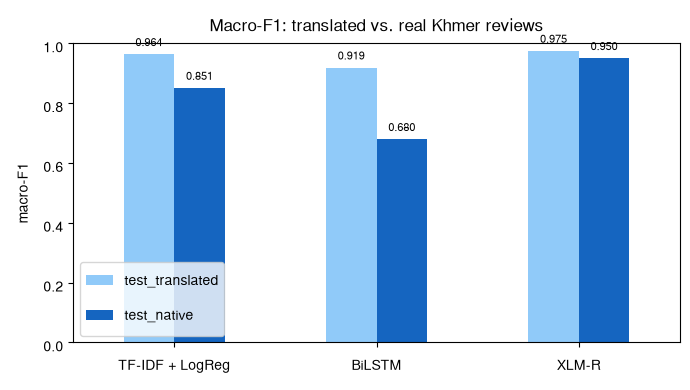

In [6]:
scores = pd.DataFrame({test_set: [metrics[key][test_set]["macro_f1"] for key in MODELS] for test_set in TEST_SETS},
                      index=list(MODELS.values()))
scores["translation gap"] = (scores["test_native"] - scores["test_translated"]).round(3)
print(scores)

ax = scores[TEST_SETS].plot(kind="bar", figsize=(7, 4), color=["#90caf9", "#1565c0"], ylim=(0, 1))
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
plt.title("Macro-F1: translated vs. real Khmer reviews")
plt.ylabel("macro-F1")
plt.xticks(rotation=0)
plt.legend(["test_translated", "test_native" + (" (silver labels)" if LABEL_SOURCE == "silver" else "")])
plt.tight_layout()
plt.savefig("results/figures/05_translation_gap.png", dpi=150)
plt.show()

| Model | test_translated | test_native | Translation gap |
|---|---|---|---|
| TF-IDF + LogReg | 0.964 | 0.851 | −0.113 |
| BiLSTM | 0.919 | 0.680 | −0.239 |
| **XLM-R** | **0.975** | **0.950** | **−0.025** |

All models were trained only on **translated** Khmer and lose accuracy on reviews **written in Khmer**. Real reviews are
shorter, informal, 79% complaints, and use words the translations never use (20.8% unknown words for the BiLSTM).
- The **BiLSTM** loses the most (−0.24): its vocabulary comes only from the translations.
- **TF-IDF** loses less (−0.11): its character pieces still match unknown words.
- **XLM-R** almost closes the gap (−0.025): it was pretrained on real Khmer web text and has (almost) no unknown pieces.

→ This answers the proposal's main question: **translate-train works for Khmer, if the model already knows real Khmer from pretraining.**

### 4. Confidence Intervals (Bootstrap)

test_native has only a few hundred reviews, so a score could be a bit higher or lower just by chance.
The **bootstrap** estimates how much:

1. draw 218 reviews from test_native **with replacement** (some reviews twice, some not at all)
2. compute the macro-F1 on this new sample
3. repeat **1,000 times** (seed 45) → the middle 95% of the 1,000 scores is the **95% confidence interval**

If the intervals of two models **overlap a lot**, the difference between them may not be reliable.

In [7]:
def bootstrap_macro_f1(y_true, y_pred, n_resamples=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = []
    for _ in range(n_resamples):
        idx = rng.integers(0, n, n)                      # sample n reviews with replacement
        scores.append(f1_score(y_true[idx], y_pred[idx], average="macro", labels=label_names, zero_division=0))
    return np.percentile(scores, 2.5), np.percentile(scores, 97.5)

ci_rows = []
for key, name in MODELS.items():
    for test_set in TEST_SETS:
        p = predictions[(key, test_set)]
        y_true, y_pred = p["true_label"].values, p["pred_label"].values
        low, high = bootstrap_macro_f1(y_true, y_pred)
        ci_rows.append({"model": name, "test set": test_set,
                        "macro-F1": round(f1_score(y_true, y_pred, average="macro"), 3),
                        "95% CI": f"[{low:.3f}, {high:.3f}]", "low": low, "high": high})
ci = pd.DataFrame(ci_rows)
print(ci.drop(columns=["low", "high"]).to_string(index=False))

          model        test set  macro-F1         95% CI
TF-IDF + LogReg test_translated     0.964 [0.944, 0.980]
TF-IDF + LogReg     test_native     0.851 [0.792, 0.903]
         BiLSTM test_translated     0.919 [0.891, 0.944]
         BiLSTM     test_native     0.680 [0.608, 0.741]
          XLM-R test_translated     0.975 [0.958, 0.989]
          XLM-R     test_native     0.950 [0.909, 0.981]


#### Confidence intervals as a chart

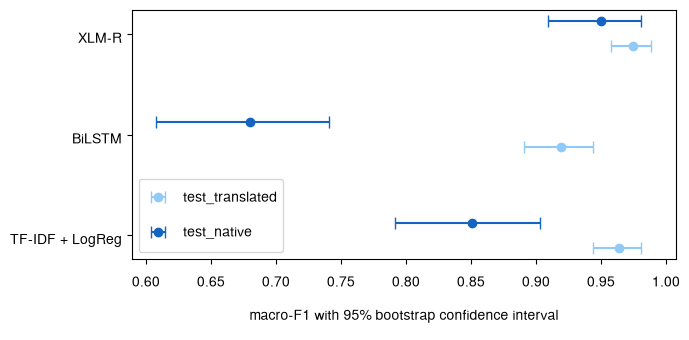

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, test_set in enumerate(TEST_SETS):
    part = ci[ci["test set"] == test_set].reset_index(drop=True)
    y = np.arange(len(part)) + i * 0.25
    ax.errorbar(part["macro-F1"], y, xerr=[part["macro-F1"] - part["low"], part["high"] - part["macro-F1"]],
                fmt="o", capsize=4, label=test_set, color=["#90caf9", "#1565c0"][i])
ax.set_yticks(np.arange(len(MODELS)) + 0.125)
ax.set_yticklabels(list(MODELS.values()))
ax.set_xlabel("macro-F1 with 95% bootstrap confidence interval")
ax.legend()
plt.tight_layout()
plt.savefig("results/figures/05_confidence_intervals.png", dpi=150)
plt.show()

- **test_native** (gold labels): the three intervals do **not overlap** (BiLSTM [0.608, 0.741] < TF-IDF [0.792, 0.903]
  < XLM-R [0.909, 0.981]). So even with only 214 reviews, the ranking **XLM-R > TF-IDF > BiLSTM** on real Khmer reviews is
  reliable – although the TF-IDF and XLM-R intervals almost touch (0.903 vs. 0.909).
- **test_translated**: TF-IDF [0.944, 0.980] and XLM-R [0.958, 0.989] **overlap a lot**, so the difference between
  0.964 and 0.975 may be chance. The BiLSTM interval [0.891, 0.944] only touches TF-IDF's lower end.
- The intervals are wide on test_native (about ±0.03 to ±0.07) because it is small. They only measure sampling
  uncertainty; the gold labels themselves are very consistent (two annotators, kappa 0.902).

### 5. Per-class Comparison

F1 score of each class, for each model and test set.

test set        test_translated          test_native         
class                  negative positive    negative positive
model                                                        
TF-IDF + LogReg           0.964    0.964       0.930    0.772
BiLSTM                    0.917    0.921       0.786    0.573
XLM-R                     0.975    0.975       0.979    0.921


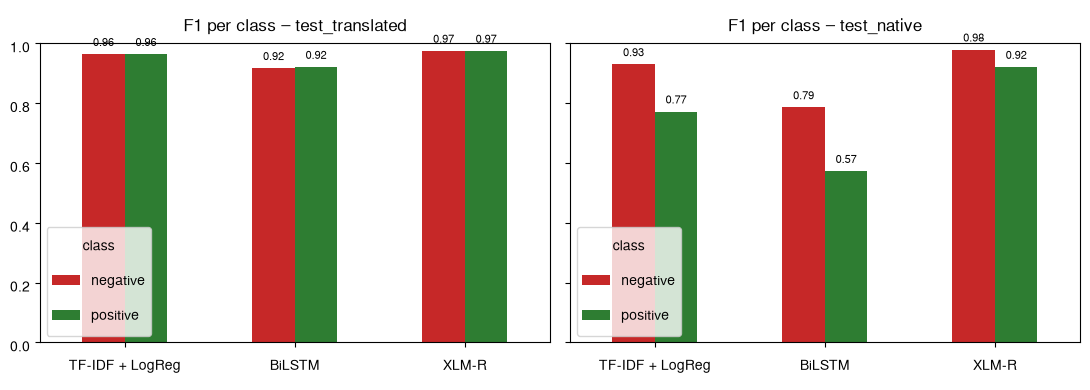

In [9]:
rows = []
for key, name in MODELS.items():
    for test_set in TEST_SETS:
        p = predictions[(key, test_set)]
        f1s = f1_score(p["true_label"], p["pred_label"], average=None, labels=label_names)
        for label, value in zip(label_names, f1s):
            rows.append({"model": name, "test set": test_set, "class": label, "F1": round(value, 3)})
per_class = pd.DataFrame(rows)
print(per_class.pivot_table(index="model", columns=["test set", "class"], values="F1", sort=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, test_set in zip(axes, TEST_SETS):
    table = per_class[per_class["test set"] == test_set].pivot(index="model", columns="class", values="F1")
    table = table.loc[list(MODELS.values()), label_names]
    table.plot(kind="bar", ax=ax, color=["#c62828", "#2e7d32"], ylim=(0, 1))
    for container in ax.containers:
        ax.bar_label(container, fmt="%.2f", fontsize=8)
    ax.set_title(f"F1 per class – {test_set}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("results/figures/05_per_class_f1.png", dpi=150)
plt.show()

- On **test_translated** both classes are about equally good for every model (balanced data).
- On **test_native** the **positive** class is the weak one for all models (TF-IDF 0.772, BiLSTM 0.573, XLM-R 0.921),
  while negative stays high (0.930, 0.786, 0.979). There are only 44 positive reviews, so every real complaint predicted
  as "positive" hurts the positive precision a lot.
- XLM-R has the smallest difference between the classes (0.979 vs. 0.921).

### 6. Error Analysis

#### 6.1 Which reviews are wrong?

For every review we check which models got it right.

In [10]:
both = []
for test_set in TEST_SETS:
    table = predictions[("xlmr", test_set)][["row_id", "text_km", "true_label"]].copy()
    for key in MODELS:
        table[key] = predictions[(key, test_set)]["pred_label"].values
    table["test_set"] = test_set
    both.append(table)
errors = pd.concat(both, ignore_index=True)
errors = errors.merge(reviews[["row_id", "text", "language_group", "translation_issue"]], on="row_id", how="left")
for key in MODELS:
    errors[f"{key}_ok"] = errors[key] == errors["true_label"]

summary = []
for test_set in TEST_SETS:
    part = errors[errors["test_set"] == test_set]
    summary.append({
        "test set": test_set, "reviews": len(part),
        "all 3 models wrong": int((~part["tfidf_logreg_ok"] & ~part["bilstm_ok"] & ~part["xlmr_ok"]).sum()),
        "only XLM-R right": int((~part["tfidf_logreg_ok"] & ~part["bilstm_ok"] & part["xlmr_ok"]).sum()),
        "only XLM-R wrong": int((part["tfidf_logreg_ok"] & part["bilstm_ok"] & ~part["xlmr_ok"]).sum()),
        "XLM-R wrong (total)": int((~part["xlmr_ok"]).sum()),
    })
pd.DataFrame(summary)

,test set,reviews,all 3 models wrong,only XLM-R right,only XLM-R wrong,XLM-R wrong (total)
0,test_translated,358,3,4,5,9
1,test_native,214,2,16,1,7


#### Reviews that all three models got wrong

In [11]:
all_wrong = errors[~errors["tfidf_logreg_ok"] & ~errors["bilstm_ok"] & ~errors["xlmr_ok"]]
for _, r in all_wrong.iterrows():
    print(f"[{r['test_set']} | row {r['row_id']} | true: {r['true_label']}] {r['text_km'][:160]}")

[test_translated | row 1336 | true: negative] អាកប្បកិរិយាល្អ តែត្រូវបង្កើនការប្រុងប្រយ័ត្នពេលនៅលើផ្លូវមានចរាចរណ៍ច្រើន។
[test_translated | row 1672 | true: negative] ត្រូវម៉ោង ឈប់សម្រាកខ្លី និងអង្គុយស្រួល។ អ្នកបើកបរបើករោលរាលបន្តិច ប៉ុន្តែនេះជាកម្ពុជាហើយ!
[test_translated | row 3834 | true: negative] បើម៉ាស៊ីនត្រជាក់ដំណើរការល្អជាងនេះ នឹងជាដំណើរល្អ។
[test_native | row 2962 | true: negative] សូមរកកន្លែងឈប់ញំាបាយដែលមានអនាម័យ និងសេវាល្អជាងនិងផង (ម្ហូបហៅជាង1h មិនបានញុំា)។ សូមអរគុណ
[test_native | row 3160 | true: negative] សួស្តី ខ្ញុំបានទិញសំបុត្រធ្វេីដំណេីរទៅសៀមរាបនិងត្រលប់មកវិញផងដែរ ពេលទៅមានអារម្មណ៍ល្អណាស់ឡានជិះទៅមានផាសុខភាពពេញចិត្តនិងអ្នកបេីកបរផងដែរ ប៉ុន្តែពេលមកវិញជិះឡានមួយទៀត


#### Reviews that only XLM-R got right (a few examples)

In [12]:
only_xlmr = errors[~errors["tfidf_logreg_ok"] & ~errors["bilstm_ok"] & errors["xlmr_ok"]]
for _, r in only_xlmr.head(8).iterrows():
    print(f"[{r['test_set']} | row {r['row_id']} | true: {r['true_label']}] {r['text_km'][:160]}")

[test_translated | row 3568 | true: positive] ដំណើរគ្មានរឿងរញ៉េរញ៉ៃ រួមទាំងដំណើរការអន្តោប្រវេសន៍ផង។ គួរឱ្យណែនាំ។
[test_translated | row 678 | true: negative] អ្វីដែលខ្ញុំត្អូញត្អែរតែមួយគឺជាទូទៅអ្នកបើកបរបើកលឿនពេកបន្តិច ហើយយើងបានបុកឆ្កែមួយក្បាលស្លាប់តាមផ្លូវ។ ប៉ុន្តែដំណើរនេះល្អណាស់ គួរឱ្យធូរចិត្តដែលឈប់តិច និងខ្លី មិនដូ
[test_translated | row 2118 | true: positive] មូលហេតុដែលខ្ញុំឱ្យ ៤ លើ ៥ គឺកៅអីដែលខ្ញុំកក់ត្រូវបានឱ្យទៅអ្នកផ្សេង។ ហាក់ដូចជាអ្នកត្រូវទៅស្ថានីយ ហើយប្តូរសំបុត្រដែលបានបោះពុម្ពយកសំបុត្ររបស់ស្ថានីយ។ ក្រៅពីនេះ ដំណើ
[test_translated | row 1001 | true: positive] រថយន្តវ៉ានស្អាតខ្លាំងណាស់ តែគេទទួលអីវ៉ាន់បន្ថែមច្រើន ហើយដាក់នៅមុខជើងខ្ញុំក្បែរទ្វារ។ ពេលខ្លះអ្នកបើកបរបើកលឿនខ្លាំង តែគាត់គោរពពេលវេលា ហើយជាដំណើរល្អគួរសម។
[test_native | row 877 | true: negative] ឈប់ឥតល្ហែ
[test_native | row 910 | true: positive] ទៀងទាត់ពេលវេលា
[test_native | row 964 | true: negative] បេីកបរត្រូវប្រយ័ត្នបន្តិច​ ! ពេលវ៉ាគេម្តងៗគួរអោយខ្លាច!
[test_native | row 1845 | true: negative] ការធ្វើដំណើរយឺតយ៉ាវបន្តិច


#### 6.2 Why are they wrong? Error categories

We **read** the reviews that **XLM-R** (the best model) still gets wrong — up to 30, test_native first — and put each one
into **one** category. The categories were assigned by reading every review (the analysis was done with the help of Claude
and checked against the text), not by a program:

| Category | Meaning |
|---|---|
| negation | a negation word (មិន, ទេ, គ្មាន, not…) changes the meaning |
| indirect/polite complaint | a complaint said politely or as a wish/suggestion |
| mixed sentiment | praise and complaint in the same review |
| sarcasm | the words say the opposite of what is meant |
| emoji-only | only emojis |
| code-switching | Khmer mixed with English words |
| translation issue | the Khmer translation lost or changed the meaning |
| possible labeling error | our (silver) label itself may be wrong |

In [13]:
xlmr_wrong = errors[~errors["xlmr_ok"]].copy()
xlmr_wrong["order"] = (xlmr_wrong["test_set"] != "test_native").astype(int)   # test_native first
xlmr_wrong = xlmr_wrong.sort_values(["order", "row_id"]).head(30)
print(f"XLM-R errors analysed: {len(xlmr_wrong)} "
      f"({(xlmr_wrong['test_set'] == 'test_native').sum()} test_native, {(xlmr_wrong['test_set'] == 'test_translated').sum()} test_translated)")
for _, r in xlmr_wrong.iterrows():
    print(f"\n[{r['test_set']} | row {r['row_id']} | true: {r['true_label']} | XLM-R: {r['xlmr']} | {r['language_group']}]")
    print("  text_km:", r["text_km"][:220])
    if r["test_set"] == "test_translated":
        print("  original:", r["text"][:220])

XLM-R errors analysed: 16 (7 test_native, 9 test_translated)

[test_native | row 1759 | true: negative | XLM-R: positive | code_switched]
  text_km: សូមព្យាយាមចេញដំណើរឱ្យទៀងទាត់
Please try to depart on time! It was 10-minute delay when I used your service.

[test_native | row 1874 | true: positive | XLM-R: negative | pure_khmer]
  text_km: សភាពខាងក្នុងទ្បានរៀងចាស់បន្តិចតែអាចទួលយកបាន

[test_native | row 2935 | true: negative | XLM-R: positive | pure_khmer]
  text_km: គួរជ្រើសរើសកន្លែងហូបបាយដែលល្អនិងមានអនាម័យ ជាពិសេសបន្ទប់ទឹក

[test_native | row 2962 | true: negative | XLM-R: positive | pure_khmer]
  text_km: សូមរកកន្លែងឈប់ញំាបាយដែលមានអនាម័យ និងសេវាល្អជាងនិងផង (ម្ហូបហៅជាង1h មិនបានញុំា)។ សូមអរគុណ

[test_native | row 3160 | true: negative | XLM-R: positive | pure_khmer]
  text_km: សួស្តី ខ្ញុំបានទិញសំបុត្រធ្វេីដំណេីរទៅសៀមរាបនិងត្រលប់មកវិញផងដែរ ពេលទៅមានអារម្មណ៍ល្អណាស់ឡានជិះទៅមានផាសុខភាពពេញចិត្តនិងអ្នកបេីកបរផងដែរ ប៉ុន្តែពេលមកវិញជិះឡានមួយទៀតមិនមែនជាឡានត្រូវទៅទេមានអារម្មណ៍ឈឺក្បាលវិលមុខមេីលផ្លូ

The table below is our **manual** reading of each review above (category + short English meaning).

In [14]:
ERROR_CATEGORIES = {
    1759: ('indirect/polite complaint', "'Please try to depart on time! It was a 10-minute delay…' (Khmer + English)"),
    1874: ('mixed sentiment', "'The inside of the car is a bit old, but acceptable'"),
    2935: ('indirect/polite complaint', "'You should choose a good, hygienic place to eat, especially the toilets'"),
    2962: ('indirect/polite complaint', "'Please find a cleaner food stop with better service (food took over 1 h, we couldn't eat). Thank you'"),
    3160: ('mixed sentiment', "'Going there was great and comfortable… but the return car was the wrong one, cramped, I got a headache 🙁'"),
    3183: ('mixed sentiment', "'It is good but a bit narrow. A little hard to place my legs' (English + Khmer)"),
    3259: ('very short review', "'Their fast (van) arrived 1 hour early' – both annotators say positive; the model reads 'fast' as a speeding complaint"),
    2923: ('mixed sentiment', "'Average ride, driver was safe… but he blasted music for 6 hours, giving me a headache'"),
    1336: ('indirect/polite complaint', "'Positive approach but need to improve the vigilance on the busy road'"),
    1672: ('possible labeling error', "'On time, short stopover and comfy. The driver was a bit crazy, but it is Cambodia!' – strict safety rule R1 (silver label)"),
    3834: ('indirect/polite complaint', "'If the air conditioning was working better, it would have been a fine trip'"),
    1703: ('mixed sentiment', "'Delayed half an hour… the driver was highly skilled to speed up… AC acceptable'"),
    1397: ('mixed sentiment', "'A long ride in a full, crowded van, but it was as advertised; I could choose my seat'"),
    1083: ('very short review', "'So hot' (ក្តៅណាស់) – two words, no context"),
    3809: ('factual complaint (no opinion words)', "'Staff put a stranger in the bed I paid for… the bus arrived 1 hour late' – a story without negative words"),
    439: ('possible labeling error', "'Passing on blind corners… some passings made us nervous, but overall it was fine' – strict safety rule R1 (silver label)"),
}

categorized = xlmr_wrong.assign(
    category=xlmr_wrong["row_id"].map(lambda r: ERROR_CATEGORIES.get(r, ("(not categorized)", ""))[0]),
    meaning=xlmr_wrong["row_id"].map(lambda r: ERROR_CATEGORIES.get(r, ("", ""))[1]),
)
counts = categorized["category"].value_counts().rename("reviews").to_frame()
counts

,reviews
category,
mixed sentiment,6
indirect/polite complaint,5
very short review,2
possible labeling error,2
factual complaint (no opinion words),1


#### Two examples per category

In [15]:
pd.set_option("display.max_colwidth", 120)
examples = categorized.groupby("category", sort=False).head(2)
examples[["category", "test_set", "true_label", "xlmr", "text_km", "meaning"]].sort_values("category")

,category,test_set,true_label,xlmr,text_km,meaning
342,factual complaint (no opinion words),test_translated,negative,positive,ខ្ញុំកក់គ្រែ ២ ព្រោះខ្ពស់ខ្លាំង និងមិនចង់ចែកគ្រែជាមួយអ្នកមិនស្គាល់ តែគួរឱ្យភ្ញាក់ផ្អើល បុគ្គលិកដាក់មនុស្សម្នាក់ក្បែរ...,'Staff put a stranger in the bed I paid for… the bus arrived 1 hour late' – a story without negative words
422,indirect/polite complaint,test_native,negative,positive,សូមព្យាយាមចេញដំណើរឱ្យទៀងទាត់\r\nPlease try to depart on time! It was 10-minute delay when I used your service.,'Please try to depart on time! It was a 10-minute delay…' (Khmer + English)
488,indirect/polite complaint,test_native,negative,positive,គួរជ្រើសរើសកន្លែងហូបបាយដែលល្អនិងមានអនាម័យ ជាពិសេសបន្ទប់ទឹក,"'You should choose a good, hygienic place to eat, especially the toilets'"
447,mixed sentiment,test_native,positive,negative,សភាពខាងក្នុងទ្បានរៀងចាស់បន្តិចតែអាចទួលយកបាន,"'The inside of the car is a bit old, but acceptable'"
513,mixed sentiment,test_native,negative,positive,សួស្តី ខ្ញុំបានទិញសំបុត្រធ្វេីដំណេីរទៅសៀមរាបនិងត្រលប់មកវិញផងដែរ ពេលទៅមានអារម្មណ៍ល្អណាស់ឡានជិះទៅមានផាសុខភាពពេញចិត្តនិ...,"'Going there was great and comfortable… but the return car was the wrong one, cramped, I got a headache 🙁'"
355,possible labeling error,test_translated,negative,positive,ការជិះនេះជាបទពិសោធន៍មួយបែប។ ការបើកបរនៅកម្ពុជាខុសពីអាមេរិកខាងជើង ដូច្នេះការវ៉ានៅផ្លូវកោងដែលមើលមិនឃើញមុខ ពេលឡានដឹកទំនិ...,"'Passing on blind corners… some passings made us nervous, but overall it was fine' – strict safety rule R1 (silver l..."
196,possible labeling error,test_translated,negative,positive,ត្រូវម៉ោង ឈប់សម្រាកខ្លី និងអង្គុយស្រួល។ អ្នកបើកបរបើករោលរាលបន្តិច ប៉ុន្តែនេះជាកម្ពុជាហើយ!,"'On time, short stopover and comfy. The driver was a bit crazy, but it is Cambodia!' – strict safety rule R1 (silver..."
529,very short review,test_native,positive,negative,លឿនរបស់គេដល់មុន១ម៉ោង,'Their fast (van) arrived 1 hour early' – both annotators say positive; the model reads 'fast' as a speeding complaint
324,very short review,test_translated,negative,positive,ក្តៅណាស់។,"'So hot' (ក្តៅណាស់) – two words, no context"


- **All three models wrong**: 2 test_native reviews (3 translated). **Only XLM-R right**: 16 test_native reviews
  (4 translated). **Only XLM-R wrong**: 1 test_native review (5 translated). XLM-R's advantage comes mostly from real Khmer reviews.
- XLM-R makes **16 mistakes** in total (7 test_native + 9 test_translated); we read all of them:

| Category | Reviews | What happens |
|---|---|---|
| mixed sentiment | 6 | praise and complaint together; the model picks the other side (e.g. *"a bit old, but acceptable"* → predicted negative) |
| indirect/polite complaint | 5 | a complaint written as a polite wish or suggestion: *"you should choose a hygienic place to eat"*, *"…Thank you"* → predicted positive |
| very short review | 2 | *"So hot"*, *"their fast van arrived 1 hour early"*: too little context (the model reads "fast" as speeding) |
| possible labeling error | 2 | both in test_translated (silver labels): our strict **safety rule (R1)** made them negative although the writer was satisfied |
| factual complaint (no opinion words) | 1 | a problem told as a story, without negative words |

- The 7 test_native mistakes are all **real model errors**: their labels are gold (two annotators). The 2 possible
  labeling errors are in test_translated, which uses silver labels.
- **No** remaining XLM-R error is caused by **negation**, **sarcasm**, **emoji-only** reviews or a **translation issue**:
  XLM-R handles negation well (see the examples in notebook 04).
- **Code-switching**: 2 of the 7 test_native errors are code-switched (2 of 21 code-switched reviews, vs. 5 of 193 pure Khmer),
  but these numbers are too small for a conclusion.
- **Indirect/polite complaints** are still the hardest real problem: polite words (សូម "please", អរគុណ "thank you", ល្អ "good")
  make a complaint look positive. These are exactly the complaints a business should not miss.

### 7. Observations and Limitations

#### Results (all numbers from `results/metrics/`)

| | TF-IDF + LogReg | BiLSTM | **XLM-R** |
|---|---|---|---|
| test_translated macro-F1 | 0.964 | 0.919 | **0.975** |
| test_native macro-F1 (gold labels) [95% CI] | 0.851 [0.792, 0.903] | 0.680 [0.608, 0.741] | **0.950** [0.909, 0.981] |
| Trainable weights | 65,481 | 908,998 | 278,045,186 |

- **Best model: fine-tuned XLM-R**, reliably better than the other two on real Khmer reviews (non-overlapping 95% intervals),
  and the only model that also gets the indirect complaint example right.
- **TF-IDF + Logistic Regression** is a strong, cheap and explainable baseline (0.5 s on a CPU, readable word weights).
- **The BiLSTM is the worst**: a more complex model is not automatically better. With 2,858 training reviews and a vocabulary
  from translations, it overfits and does not know 20.8% of the words in real Khmer reviews.

#### Label quality
- **Gold labels** (test_native): two annotators, 96.4% agreement, **Cohen's kappa 0.902**; 8 disagreements decided together.
- **Silver (AI) labels**: they agree with the gold labels on **98.2%** of the real-Khmer test reviews. In a separate human
  check of 150 random reviews (one team member, `data/labels/human_review_results.md`), the human agreed with the AI on
  **98.0%** of the reviews both called positive or negative, but confirmed only 54% of the AI's *neutral* labels –
  another reason to use 2 classes.

#### Limitations
- **Small native test set**: 214 reviews (only 44 positive, 21 code-switched) → wide confidence intervals; the
  pure-Khmer vs. code-switched comparison is not reliable.
- **Silver labels for training**: the training, validation and test_translated labels were produced by an AI (Claude);
  the error analysis found 2 likely labeling problems there, caused by our strict safety rule. Only test_native has gold labels.
- **Translated training data**: the models never saw a real Khmer review during training.
- **Not run**: the proposal's comparison of native vs. translated **training** data, because all native reviews were needed
  for the test set.
- **2 classes instead of 3**: neutral reviews (5.7%, only 9 in Khmer) were too few, and humans often disagreed with them.
- **One domain** (bus/van/ferry), **one run** with seed 45 (no average over several seeds), and the BiLSTM was not tuned
  beyond the planned settings.

#### Ideas for improvement
- Collect **more reviews written in Khmer** for training, so the native vs. translated training comparison becomes possible.
- Add training examples of **polite/indirect complaints**, the main remaining error.
- For the neural network: use subword or character embeddings to avoid unknown words.
- Repeat the training with several seeds and report the average.

#### Back to our problem statement
Cambodian businesses receive more and more feedback in Khmer, but there are almost no Khmer sentiment tools or labeled data.
This project shows a practical route: label reviews from their text, train on **Khmer translations** of existing reviews,
and fine-tune a **multilingual pretrained transformer**. Without a single native Khmer review in training, XLM-R reached a
macro-F1 of **0.950** on real Khmer reviews labeled by humans. The errors that remain are mostly polite or indirect
complaints, so a business using such a tool should still read the uncertain predictions itself.